# PMOS-prediksjon
Målet med denne notebooken er å forstå datasettet før modellering. 
Datakvalitet, fordeling av målvariabelen og hvilke selvrapporterte symptomer som henger sammen med PCOS.
Datasett er hentet fra Kaggle: Polycystic ovary syndrome (PCOS), Prasoon Kottarathil, Kaggle. 541 pasienter fra 10 sykehus i Kerala, India.

## 1.Importer og lasting
Excel-filen har to ark (Instructions og Full_new). Dataene ligger i Full_new.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_excel("../data/PCOS_data_without_infertility.xlsx", sheet_name="Full_new")



**Fra arket Instructions:**
Ja/Nei-spørsmål er kodet 1 = ja, 0 = nei. 
Kodingen av `Cycle(R/I)` (2/4/5) og betydningen av `Cycle length(days)` er ikke dokumentert, så vi tolker 2 = regelmessig og 4 = uregelmessig syklus.

In [2]:
df.columns = df.columns.str.strip() # fjerner mellomrom i kolonnenavn
print(df.shape)
df.head()

(541, 45)


,Sl. No,Patient File No.,PCOS (Y/N),Age (yrs),Weight (Kg),Height(Cm),BMI,Blood Group,Pulse rate(bpm),RR (breaths/min),...,Fast food (Y/N),Reg.Exercise(Y/N),BP _Systolic (mmHg),BP _Diastolic (mmHg),Follicle No. (L),Follicle No. (R),Avg. F size (L) (mm),Avg. F size (R) (mm),Endometrium (mm),Unnamed: 44
0,1,1,0,28,44.6,152.0,19.300000,15,78,22,...,1.0,0,110,80,3,3,18.0,18.0,8.5,NaN
1,2,2,0,36,65.0,161.5,24.921163,15,74,20,...,0.0,0,120,70,3,5,15.0,14.0,3.7,NaN
2,3,3,1,33,68.8,165.0,25.270891,11,72,18,...,1.0,0,120,80,13,15,18.0,20.0,10.0,NaN
3,4,4,0,37,65.0,148.0,29.674945,13,72,20,...,0.0,0,120,70,2,2,15.0,14.0,7.5,NaN
4,5,5,0,25,52.0,161.0,20.060954,11,72,18,...,0.0,0,120,80,3,4,16.0,14.0,7.0,NaN


## 2.Oversikt over kolonnene: 
Sjekker datatyper og grunnleggende statistikk for å finne kolonner med feil

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541 entries, 0 to 540
Data columns (total 45 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Sl. No                  541 non-null    int64  
 1   Patient File No.        541 non-null    int64  
 2   PCOS (Y/N)              541 non-null    int64  
 3   Age (yrs)               541 non-null    int64  
 4   Weight (Kg)             541 non-null    float64
 5   Height(Cm)              541 non-null    float64
 6   BMI                     541 non-null    float64
 7   Blood Group             541 non-null    int64  
 8   Pulse rate(bpm)         541 non-null    int64  
 9   RR (breaths/min)        541 non-null    int64  
 10  Hb(g/dl)                541 non-null    float64
 11  Cycle(R/I)              541 non-null    int64  
 12  Cycle length(days)      541 non-null    int64  
 13  Marraige Status (Yrs)   540 non-null    float64
 14  Pregnant(Y/N)           541 non-null    int64  
 15  

In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Sl. No,541.0,271.000000,156.317519,1.000000,136.000000,271.000000,406.000000,541.000000
Patient File No.,541.0,271.000000,156.317519,1.000000,136.000000,271.000000,406.000000,541.000000
PCOS (Y/N),541.0,0.327172,0.469615,0.000000,0.000000,0.000000,1.000000,1.000000
Age (yrs),541.0,31.430684,5.411006,20.000000,28.000000,31.000000,35.000000,48.000000
Weight (Kg),541.0,59.637153,11.028287,31.000000,52.000000,59.000000,65.000000,108.000000
Height(Cm),541.0,156.484835,6.033545,137.000000,152.000000,156.000000,160.000000,180.000000
BMI,541.0,24.311285,4.056399,12.417882,21.641274,24.238227,26.634958,38.900000
Blood Group,541.0,13.802218,1.840812,11.000000,13.000000,14.000000,15.000000,18.000000
Pulse rate(bpm),541.0,73.247689,4.430285,13.000000,72.000000,72.000000,74.000000,82.000000
RR (breaths/min),541.0,19.243993,1.688629,16.000000,18.000000,18.000000,20.000000,28.000000


## 3. Datakvalitet:
Sjekker manglende verdier og duplikater og fjerner ID-kolonner som ikke har nyttig informasjon 

In [5]:
mangler = df.isna().sum()
print(mangler[mangler > 0])
print("Duplikater:", df.duplicated().sum())

Marraige Status (Yrs)      1
Fast food (Y/N)            1
Unnamed: 44              539
dtype: int64
Duplikater: 0


In [6]:
df = df.drop(columns=["Sl. No", "Patient File No.", "Unnamed: 44"], errors="ignore")
print(df.shape)

(541, 42)


**Funn:**
- `II beta-HCG` og `AMH` er lest inn som tekst og må konverteres til tall.
- 1 manglende verdi i `Marraige Status (Yrs)` og 1 i `Fast food (Y/N)`. Ingen duplikater.
- Umulige verdier: puls 13, blodtrykk 12/8. Trolig tastefeil.
- ID-kolonnene og den tomme `Unnamed: 44` er fjernet.

## 4. Målvariabelen:
Sjekker hvor mange som har PCOS fordi ubalanse opvirker hvilken metrikk vi bør bruke

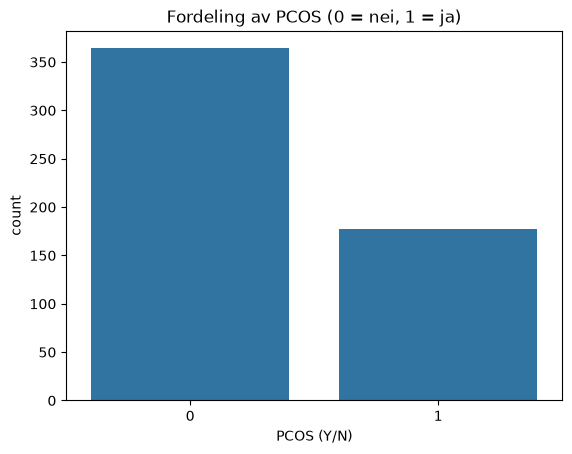

PCOS (Y/N)
0    0.67
1    0.33
Name: proportion, dtype: float64

In [7]:
sns.countplot(x="PCOS (Y/N)", data=df)
plt.title("Fordeling av PCOS (0 = nei, 1 = ja)")
plt.show()

df["PCOS (Y/N)"].value_counts(normalize=True).round(2)

**Funn:** 67 % har ikke PCOS og 33 % har det. En modell som alltid gjetter «ikke PCOS» får dermed 67 % accuracy.

## 5. Selvrapporterte features:
Nettsiden skal bare spørre om ting brukeren vet selv (alder, BMI, syklus og symptomer)

In [8]:
print(df.columns.tolist())

['PCOS (Y/N)', 'Age (yrs)', 'Weight (Kg)', 'Height(Cm)', 'BMI', 'Blood Group', 'Pulse rate(bpm)', 'RR (breaths/min)', 'Hb(g/dl)', 'Cycle(R/I)', 'Cycle length(days)', 'Marraige Status (Yrs)', 'Pregnant(Y/N)', 'No. of aborptions', 'I   beta-HCG(mIU/mL)', 'II    beta-HCG(mIU/mL)', 'FSH(mIU/mL)', 'LH(mIU/mL)', 'FSH/LH', 'Hip(inch)', 'Waist(inch)', 'Waist:Hip Ratio', 'TSH (mIU/L)', 'AMH(ng/mL)', 'PRL(ng/mL)', 'Vit D3 (ng/mL)', 'PRG(ng/mL)', 'RBS(mg/dl)', 'Weight gain(Y/N)', 'hair growth(Y/N)', 'Skin darkening (Y/N)', 'Hair loss(Y/N)', 'Pimples(Y/N)', 'Fast food (Y/N)', 'Reg.Exercise(Y/N)', 'BP _Systolic (mmHg)', 'BP _Diastolic (mmHg)', 'Follicle No. (L)', 'Follicle No. (R)', 'Avg. F size (L) (mm)', 'Avg. F size (R) (mm)', 'Endometrium (mm)']


In [9]:
selvrapport = ["Age (yrs)", "BMI", "Cycle(R/I)", "Cycle length(days)",
               "Weight gain(Y/N)", "hair growth(Y/N)", "Skin darkening (Y/N)",
               "Hair loss(Y/N)", "Pimples(Y/N)", "Fast food (Y/N)", "Reg.Exercise(Y/N)"]

print(df["Cycle(R/I)"].value_counts())

Cycle(R/I)
2    390
4    150
5      1
Name: count, dtype: int64


In [10]:
for col in [c for c in selvrapport if "(Y/N)" in c]:
    andel = df.groupby(col)["PCOS (Y/N)"].mean().round(2)
    print(f"{col}:\n{andel}\n")

Weight gain(Y/N):
Weight gain(Y/N)
0    0.17
1    0.59
Name: PCOS (Y/N), dtype: float64

hair growth(Y/N):
hair growth(Y/N)
0    0.19
1    0.68
Name: PCOS (Y/N), dtype: float64

Skin darkening (Y/N):
Skin darkening (Y/N)
0    0.18
1    0.66
Name: PCOS (Y/N), dtype: float64

Hair loss(Y/N):
Hair loss(Y/N)
0    0.25
1    0.42
Name: PCOS (Y/N), dtype: float64

Pimples(Y/N):
Pimples(Y/N)
0    0.20
1    0.46
Name: PCOS (Y/N), dtype: float64

Fast food (Y/N):
Fast food (Y/N)
0.0    0.15
1.0    0.50
Name: PCOS (Y/N), dtype: float64

Reg.Exercise(Y/N):
Reg.Exercise(Y/N)
0    0.31
1    0.38
Name: PCOS (Y/N), dtype: float64



**Funn:**
- Størst forskjell blant dem med økt hårvekst har 68 % PCOS (mot 19 % uten), mørkere hudpartier 66 % (mot 18 %), vektøkning 59 % (mot 17 %) og fast food 50 % (mot 15 %).
- Kviser (46 % mot 20 %) og hårtap (42 % mot 25 %) skiller middels.

## 6. Visualisering: 
Forskjeller mellom gruppene og korrelasjon mellom features. 

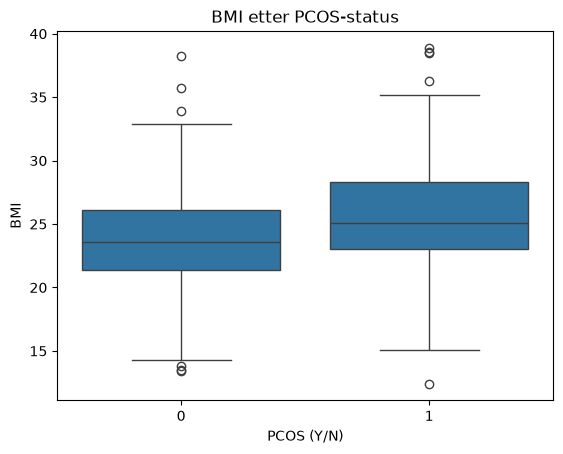

In [11]:
sns.boxplot(x="PCOS (Y/N)", y="BMI", data=df)
plt.title("BMI etter PCOS-status")
plt.show()

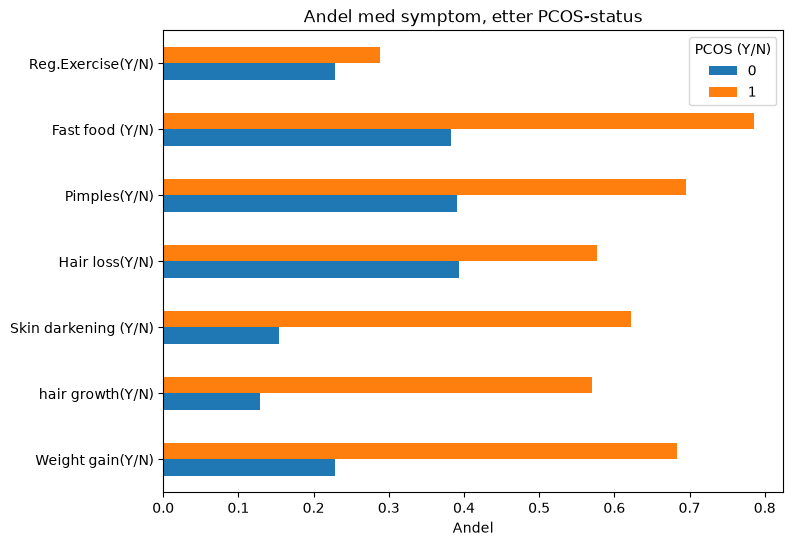

In [12]:
symptomer = [c for c in selvrapport if "(Y/N)" in c]
df.groupby("PCOS (Y/N)")[symptomer].mean().T.plot(kind="barh", figsize=(8, 6))
plt.title("Andel med symptom, etter PCOS-status")
plt.xlabel("Andel")
plt.show()

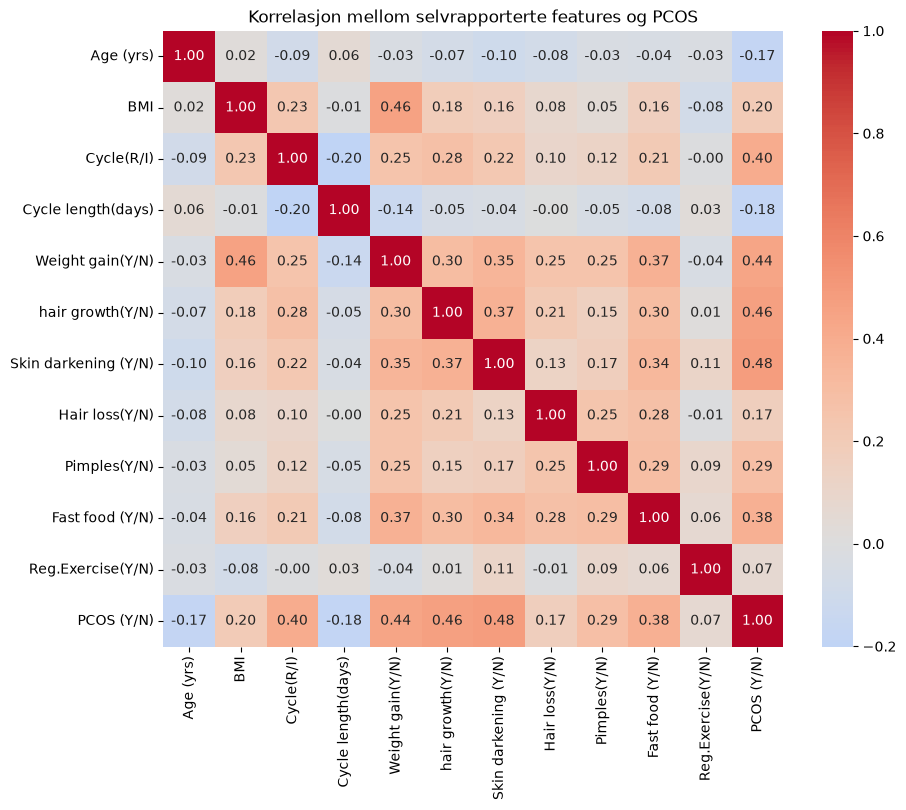

In [13]:
num = df[selvrapport + ["PCOS (Y/N)"]].apply(pd.to_numeric, errors="coerce")
plt.figure(figsize=(10, 8))
sns.heatmap(num.corr(), cmap="coolwarm", center=0, annot=True, fmt=".2f")
plt.title("Korrelasjon mellom selvrapporterte features og PCOS")
plt.show()

## 6b. Ekstra sjekker
Sjekker hva `Cycle length(days)` faktisk måler, og om midje- og hoftemål henger sammen med PCOS.

In [14]:
print(df.groupby("PCOS (Y/N)")["Cycle length(days)"].describe())
print("Antall med 0 dager per gruppe:")
print(df[df["Cycle length(days)"] == 0]["PCOS (Y/N)"].value_counts())

            count      mean       std  min  25%  50%  75%   max
PCOS (Y/N)                                                     
0           364.0  5.126374  1.264243  0.0  5.0  5.0  6.0  12.0
1           177.0  4.559322  1.821006  2.0  3.0  5.0  5.0  12.0
Antall med 0 dager per gruppe:
PCOS (Y/N)
0    1
Name: count, dtype: int64


In [15]:
mal = ["Waist(inch)", "Hip(inch)", "Waist:Hip Ratio", "Weight (Kg)", "BMI"]
df[mal + ["PCOS (Y/N)"]].corr()["PCOS (Y/N)"].sort_values(ascending=False).round(2)

PCOS (Y/N)         1.00
Weight (Kg)        0.21
BMI                0.20
Waist(inch)        0.16
Hip(inch)          0.16
Waist:Hip Ratio    0.01
Name: PCOS (Y/N), dtype: float64

**Funn:**
- `Cycle length(days)` måler trolig blødningsdager, ikke sykluslengde: median 5 og verdier mellom 2 og 12 i begge grupper. Vi gir kolonnen nytt navn til `Bleeding days`.
- PCOS-gruppen har litt kortere blødninger (snitt 4,6 mot 5,1 dager). Dette forklarer den svake negative korrelasjonen (−0,18).
- Én rad har 0 dager, i gruppen uten PCOS. Den er trolig en registreringsfeil og fjernes.
- Midje (0,16), hofte (0,16) og Waist:Hip Ratio (0,01) henger svakere sammen med PCOS enn vekt (0,21) og BMI (0,20). Tar derfor ikke med i skjemaet, og bruker BMI i stedet.

## Funn

**BMI**
- PCOS-gruppen har noe høyere BMI (median ca. 25 mot ca. 23,5), men gruppene overlapper mye. BMI alene skiller dårlig.

**Symptomer**
Se seksjon 5 

**Korrelasjon med PCOS**
- Sterkest: Skin darkening (0,48), hair growth (0,46), weight gain (0,44), uregelmessig syklus (0,40) og fast food (0,38).
- Middels: pimples (0,29) og BMI (0,20).
- Svakest: hair loss (0,17), regelmessig trening (0,07). Alder (−0,17) og sykluslengde (−0,18) har svak negativ sammenheng.
- Ingen features er sterkt korrelert med hverandre (høyest 0,46 mellom BMI og vektøkning), så vi trenger ikke fjerne noen av den grunn.


## 7. Oppsummering og videre arbeid
- Symptomene som skiller mest er skin darkening (0,48) og hårvekst (0,46). 
- 541 rader og 45 kolonner. 32,7 % har PCOS.
- `II beta-HCG` og `AMH` er lest inn som tekst og må konverteres til tall.
- `Unnamed: 44` er nesten tom og fjernes sammen med ID-kolonnene.
- 1 manglende verdi i `Marraige Status (Yrs)` og 1 i `Fast food (Y/N)`.
  - `Cycle(R/I)` har én ugyldig verdi (5) som må fjernes eller rettes.
  - `Cycle length(days)` ser ut til å måle blødningsdager, ikke sykluslengde (median 5). Kodingen er ikke dokumentert i datasettet.
  - Ja/Nei-variablene er kodet 1/0, bekreftet i arket Instructions.
  
**Forslag videre**
- Tren modell på selvrapporterte features
- Prioriter recall, siden det er verre å overse PCOS enn å gi falsk alarm.
- Sammenlign mot baseline, 67 % accuracy.
- Rens dataene: konverter tekstkolonner til tall og håndter manglende verdier.

**Begrensninger**
- Data fra én region i India, så modellen generaliserer ikke nødvendigvis til andre befolkninger.
- Lite datasett (541 pasienter).
  - Prevensjon er ikke med i datasettet. Hormonell prevensjon kan skjule symptomer og gi feil resultat.